Importing the data

In [1]:

import pandas as pd

df = pd.read_csv(
    "/workspaces/ADA-Sovereign-Spreads/data/raw/sovereign_spread_quarterly.csv"
)

df.head()

,Date,Quarter,Country,10Y Yields,GDP_Growth,Debt_GDP,Current_Account,Interest_ex,Deficit_Surplus,HCPI_rate,Unemployment_rate,10Y_Spread
0,45992,2025-Q4,DE,2.8623,0.3,63.5,4.3,1.1,-4.8,0.1,3.9,0.000
1,36526,2000-Q1,BE,5.8300,0.7,117.4,4.3,6.9,-4.8,-1.3,7.3,0.242
2,36557,2000-Q1,BE,5.7830,0.7,117.4,4.3,6.9,-4.8,2.1,7.1,0.271
3,45931,2025-Q4,DE,2.6369,0.3,63.5,4.3,1.1,-4.8,0.3,3.8,0.000
4,36586,2000-Q1,BE,5.5120,0.7,117.4,4.3,6.9,-4.8,0.5,6.9,0.293


Dimensions

In [2]:
df.shape


(3120, 12)

Data type

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3120 entries, 0 to 3119
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               3120 non-null   int64  
 1   Quarter            3120 non-null   str    
 2   Country            3120 non-null   str    
 3   10Y Yields         3120 non-null   float64
 4   GDP_Growth         3120 non-null   float64
 5   Debt_GDP           3120 non-null   float64
 6   Current_Account    3120 non-null   float64
 7   Interest_ex        3120 non-null   float64
 8   Deficit_Surplus    3120 non-null   float64
 9   HCPI_rate          3120 non-null   float64
 10  Unemployment_rate  3120 non-null   float64
 11  10Y_Spread         3120 non-null   float64
dtypes: float64(9), int64(1), str(2)
memory usage: 292.6 KB


In [4]:
# Examine how dates are stored
print(df["Date"].head(10).tolist())

[45992, 36526, 36557, 45931, 36586, 36617, 36647, 36678, 36708, 36739]


In [5]:

# Convert Excel serial numbers into dates
df["Date"] = pd.to_datetime(
    df["Date"],
    unit="D",
    origin="1899-12-30"
)

# Check the result
print(df["Date"].head(10))

0   2025-12-01
1   2000-01-01
2   2000-02-01
3   2025-10-01
4   2000-03-01
5   2000-04-01
6   2000-05-01
7   2000-06-01
8   2000-07-01
9   2000-08-01
Name: Date, dtype: datetime64[us]


Sorting by date and country

In [6]:
# Sort the dataset by date and country
df = df.sort_values(
    by=["Date", "Country"]
).reset_index(drop=True)

# Display the first 15 observations
df.head(15)

,Date,Quarter,Country,10Y Yields,GDP_Growth,Debt_GDP,Current_Account,Interest_ex,Deficit_Surplus,HCPI_rate,Unemployment_rate,10Y_Spread
0,2000-01-01,2000-Q1,AT,5.793,-0.2,70.8,1.70,4.3,-1.6,-0.4,4.3,0.205
1,2000-01-01,2000-Q1,BE,5.830,0.7,117.4,4.30,6.9,-4.8,-1.3,7.3,0.242
2,2000-01-01,2000-Q1,DE,5.588,1.6,60.4,-0.90,3.1,-1.7,0.2,8.2,0.000
3,2000-01-01,2000-Q1,ES,5.817,1.6,59.7,-5.90,3.2,0.5,0.4,12.8,0.229
4,2000-01-01,2000-Q1,FR,5.653,0.9,60.4,0.50,2.9,-4.4,0.0,9.8,0.065
5,2000-01-01,2000-Q1,GR,6.602,0.2,106.8,-10.80,10.2,-4.9,-1.3,11.5,1.014
6,2000-01-01,2000-Q1,IE,5.787,0.9,45.2,-1.70,1.7,-4.2,-0.3,4.9,0.199
7,2000-01-01,2000-Q1,IT,5.824,1.2,112.7,-0.20,6.2,-6.2,0.2,10.6,0.236
8,2000-01-01,2000-Q1,NL,5.691,1.0,59.6,2.45,3.6,-0.2,-0.3,3.9,0.103
9,2000-01-01,2000-Q1,PT,5.834,2.3,56.4,-12.80,3.0,-1.1,-0.2,5.6,0.246


Missing values ? Duplicates ?


In [7]:
# Count missing values in each column
print(df.isnull().sum())

Date                 0
Quarter              0
Country              0
10Y Yields           0
GDP_Growth           0
Debt_GDP             0
Current_Account      0
Interest_ex          0
Deficit_Surplus      0
HCPI_rate            0
Unemployment_rate    0
10Y_Spread           0
dtype: int64


In [8]:
# Check for completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check for duplicate country-date combinations
print(
    "Duplicate country-date observations:",
    df.duplicated(subset=["Country", "Date"]).sum()
)

Duplicate rows: 0
Duplicate country-date observations: 0


In [9]:
# Count observations for each country
df["Country"].value_counts().sort_index()

Country
AT    312
BE    312
DE    312
ES    312
FR    312
GR    312
IE    312
IT    312
NL    312
PT    312
Name: count, dtype: int64

Descriptive Statistics

In [12]:

# Descriptive statistics for our two target variables

df[["10Y Yields", "10Y_Spread"]].describe().round(2)

,10Y Yields,10Y_Spread
count,3120.00,3120.00
mean,3.35,1.03
std,2.71,2.37
min,-0.70,-0.12
25%,1.62,0.13
50%,3.45,0.35
75%,4.41,0.91
max,36.59,34.78


In [13]:
# Create a dataset excluding Germany for spread analysis
df_spread = df[df["Country"] != "DE"].copy()

# Compare the spread statistics
print("Original dataset:")
print(df["10Y_Spread"].describe().round(2))

print("\nWithout Germany:")
print(df_spread["10Y_Spread"].describe().round(2))

Original dataset:
count    3120.00
mean        1.03
std         2.37
min        -0.12
25%         0.13
50%         0.35
75%         0.91
max        34.78
Name: 10Y_Spread, dtype: float64

Without Germany:
count    2808.00
mean        1.15
std         2.48
min        -0.12
25%         0.20
50%         0.40
75%         1.05
max        34.78
Name: 10Y_Spread, dtype: float64


In [14]:

# Descriptive statistics for sovereign spreads by country

country_spreads = df_spread.groupby("Country")["10Y_Spread"].agg(
    ["mean", "median", "std", "min", "max"]
)

# Sort countries by their average spread
country_spreads = country_spreads.sort_values(
    by="mean",
    ascending=False
)

country_spreads.round(2)

,mean,median,std,min,max
Country,,,,,
GR,4.00,1.56,5.75,0.02,34.78
PT,1.69,0.74,2.40,-0.03,14.63
IT,1.28,1.20,1.02,0.11,5.21
IE,1.05,0.44,1.67,-0.08,8.84
ES,0.99,0.77,1.04,-0.05,5.50
BE,0.46,0.35,0.41,-0.00,2.78
FR,0.35,0.32,0.26,-0.01,1.33
AT,0.31,0.26,0.24,-0.12,1.30
NL,0.18,0.15,0.14,-0.06,0.80


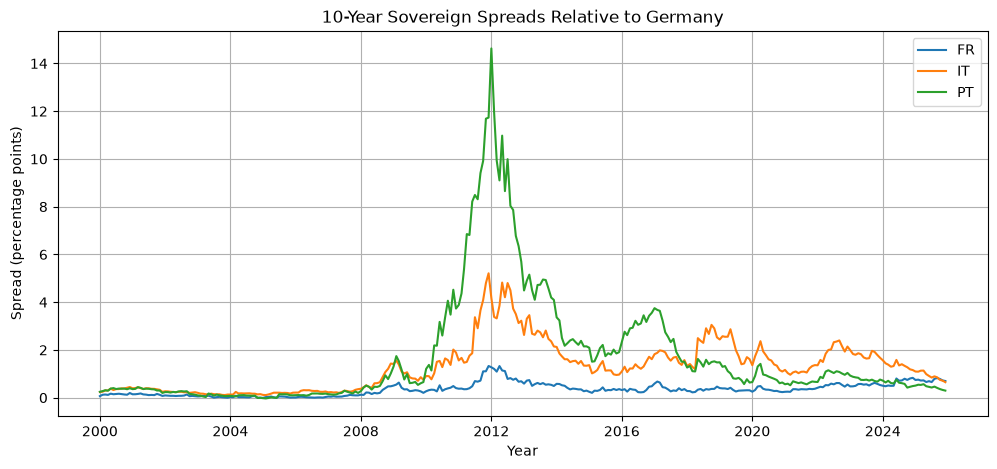

In [16]:

import matplotlib.pyplot as plt

# Select three countries to compare
countries = ["FR", "IT", "PT"]

plt.figure(figsize=(12, 5))

for country in countries:
    data = df_spread[df_spread["Country"] == country]

    plt.plot(
        data["Date"],
        data["10Y_Spread"],
        label=country
    )

plt.title("10-Year Sovereign Spreads Relative to Germany")
plt.xlabel("Year")
plt.ylabel("Spread (percentage points)")
plt.legend()
plt.grid(True)
plt.show()


In [17]:
# Measure monthly spread persistence by country

for country in ["FR", "IT", "PT"]:
    series = (
        df_spread[df_spread["Country"] == country]
        .sort_values("Date")["10Y_Spread"]
    )

    correlation = series.autocorr(lag=1)

    print(f"{country}: {correlation:.3f}")

FR: 0.965
IT: 0.972
PT: 0.982


In [18]:
# Descriptive statistics for all numerical variables

descriptive_stats = df.describe().T

# Round the results to two decimal places
descriptive_stats.round(2)


,count,mean,min,25%,50%,75%,max,std
Date,3120,2012-12-15 17:23:04.615384,2000-01-01 00:00:00,2006-06-23 12:00:00,2012-12-16 12:00:00,2019-06-08 12:00:00,2025-12-01 00:00:00,NaN
10Y Yields,3120.0,3.352734,-0.703,1.61525,3.4485,4.407,36.591,2.708127
GDP_Growth,3120.0,0.420865,-17.8,0.0,0.4,0.9,24.6,2.290844
Debt_GDP,3120.0,90.013269,23.7,63.0,85.45,109.7,212.9,35.62183
Current_Account,3120.0,0.253433,-61.9,-2.325,0.6,4.0,28.1,6.594998
Interest_ex,3120.0,2.793942,0.4,1.8,2.6,3.5,11.8,1.516518
Deficit_Surplus,3120.0,-3.386827,-41.6,-6.0,-2.7,-0.3,10.8,4.999835
HCPI_rate,3120.0,0.183782,-3.9,-0.2,0.2,0.5,4.4,0.740449
Unemployment_rate,3120.0,8.868173,2.9,5.6,7.9,10.3,28.3,4.761974
10Y_Spread,3120.0,1.032237,-0.115,0.131,0.347,0.91,34.78,2.373785


In [19]:
# Select our macroeconomic explanatory variables

fundamentals = [
    "GDP_Growth",
    "Debt_GDP",
    "Current_Account",
    "Interest_ex",
    "Deficit_Surplus",
    "HCPI_rate",
    "Unemployment_rate"
]

# Calculate correlations between explanatory variables
correlation_matrix = df[fundamentals].corr()

# Display the matrix
correlation_matrix.round(2)

,GDP_Growth,Debt_GDP,Current_Account,Interest_ex,Deficit_Surplus,HCPI_rate,Unemployment_rate
GDP_Growth,1.00,-0.04,0.06,-0.08,0.15,-0.00,-0.05
Debt_GDP,-0.04,1.00,-0.20,0.50,-0.23,-0.03,0.55
Current_Account,0.06,-0.20,1.00,-0.29,0.25,-0.02,-0.22
Interest_ex,-0.08,0.50,-0.29,1.00,-0.25,-0.02,0.35
Deficit_Surplus,0.15,-0.23,0.25,-0.25,1.00,0.00,-0.34
HCPI_rate,-0.00,-0.03,-0.02,-0.02,0.00,1.00,-0.07
Unemployment_rate,-0.05,0.55,-0.22,0.35,-0.34,-0.07,1.00


In [22]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 49.3 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Use our previously defined list of fundamentals
X = df[fundamentals].astype(float)

# Add a constant (intercept)
X = sm.add_constant(X)

# Calculate VIF for each explanatory variable
vif = pd.DataFrame()

vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

# Display results, excluding the constant
vif[vif["Variable"] != "const"].round(2)


,Variable,VIF
1,GDP_Growth,1.03
2,Debt_GDP,1.71
3,Current_Account,1.15
4,Interest_ex,1.44
5,Deficit_Surplus,1.21
6,HCPI_rate,1.01
7,Unemployment_rate,1.57


In [26]:
# Reset modelling dataset from the original data
df_model = df.copy(deep=True)

# Check the columns
print(df_model.columns.tolist())

# Verify that no lagged variables remain
print("Lagged columns remaining:",
      [col for col in df_model.columns if "_lag" in col])

['Date', 'Quarter', 'Country', '10Y Yields', 'GDP_Growth', 'Debt_GDP', 'Current_Account', 'Interest_ex', 'Deficit_Surplus', 'HCPI_rate', 'Unemployment_rate', '10Y_Spread']
Lagged columns remaining: []


In [27]:

# Verify that df_model is identical to df
print("Datasets identical:", df_model.equals(df))

# Check dimensions
print("Original:", df.shape)
print("Reset:", df_model.shape)

# Check missing observations
print("Missing values:", df_model.isna().sum().sum())

# Check duplicates
print("Duplicates:",
      df_model.duplicated(subset=["Country", "Date"]).sum())


Datasets identical: True
Original: (3120, 12)
Reset: (3120, 12)
Missing values: 0
Duplicates: 0


In [28]:

# Quarterly macroeconomic variables
quarterly_vars = [
    "GDP_Growth",
    "Debt_GDP",
    "Current_Account",
    "Interest_ex",
    "Deficit_Surplus"
]

# Verify that quarterly values are consistent
# across the three months of each quarter
check = df_model.groupby(
    ["Country", "Quarter"]
)[quarterly_vars].nunique(dropna=False)

assert (check <= 1).all().all(), \
    "Some quarterly values differ within the same quarter"

# Create one observation per country-quarter
quarterly = (
    df_model[["Country", "Quarter"] + quarterly_vars]
    .drop_duplicates(subset=["Country", "Quarter"])
    .sort_values(["Country", "Quarter"])
    .copy()
)

# Apply a one-year lag (4 quarters)
for variable in quarterly_vars:
    quarterly[f"{variable}_lag4q"] = (
        quarterly.groupby("Country")[variable].shift(4)
    )

# Merge the lagged variables into df_model
lagged_cols = [
    f"{variable}_lag4q" for variable in quarterly_vars
]

df_model = df_model.merge(
    quarterly[["Country", "Quarter"] + lagged_cols],
    on=["Country", "Quarter"],
    how="left",
    validate="many_to_one"
)


In [29]:

# Monthly macroeconomic variables
monthly_vars = [
    "HCPI_rate",
    "Unemployment_rate"
]

# Ensure chronological order
df_model = df_model.sort_values(
    ["Date", "Country"]
).reset_index(drop=True)

# Apply a one-year lag (12 months)
for variable in monthly_vars:
    df_model[f"{variable}_lag12m"] = (
        df_model.groupby("Country")[variable].shift(12)
    )

In [30]:

# Compare original columns with df
original_cols = df.columns.tolist()

unchanged = (
    df_model[original_cols]
    .sort_values(["Date", "Country"])
    .reset_index(drop=True)
    .equals(
        df.sort_values(["Date", "Country"])
        .reset_index(drop=True)
    )
)

print("Original data unchanged:", unchanged)
print("Total rows:", len(df_model))
print("Total columns:", len(df_model.columns))

print("\nLagged variables:")
print([c for c in df_model.columns if "_lag" in c])

Original data unchanged: True
Total rows: 3120
Total columns: 19

Lagged variables:
['GDP_Growth_lag4q', 'Debt_GDP_lag4q', 'Current_Account_lag4q', 'Interest_ex_lag4q', 'Deficit_Surplus_lag4q', 'HCPI_rate_lag12m', 'Unemployment_rate_lag12m']


In [31]:

# Select France, January to March, in 2000 and 2001

check_lags = df_model.loc[
    (df_model["Country"] == "FR") &
    (df_model["Date"].dt.year.isin([2000, 2001])) &
    (df_model["Date"].dt.month.isin([1, 2, 3])),
    [
        "Date",
        "Quarter",
        "GDP_Growth",
        "GDP_Growth_lag4q",
        "Debt_GDP",
        "Debt_GDP_lag4q",
        "HCPI_rate",
        "HCPI_rate_lag12m"
    ]
]

check_lags


,Date,Quarter,GDP_Growth,GDP_Growth_lag4q,Debt_GDP,Debt_GDP_lag4q,HCPI_rate,HCPI_rate_lag12m
4,2000-01-01,2000-Q1,0.9,NaN,60.4,NaN,0.0,NaN
14,2000-02-01,2000-Q1,0.9,NaN,60.4,NaN,0.1,NaN
24,2000-03-01,2000-Q1,0.9,NaN,60.4,NaN,0.5,NaN
124,2001-01-01,2001-Q1,0.5,0.9,58.7,60.4,-0.5,0.0
134,2001-02-01,2001-Q1,0.5,0.9,58.7,60.4,0.3,0.1
144,2001-03-01,2001-Q1,0.5,0.9,58.7,60.4,0.5,0.5


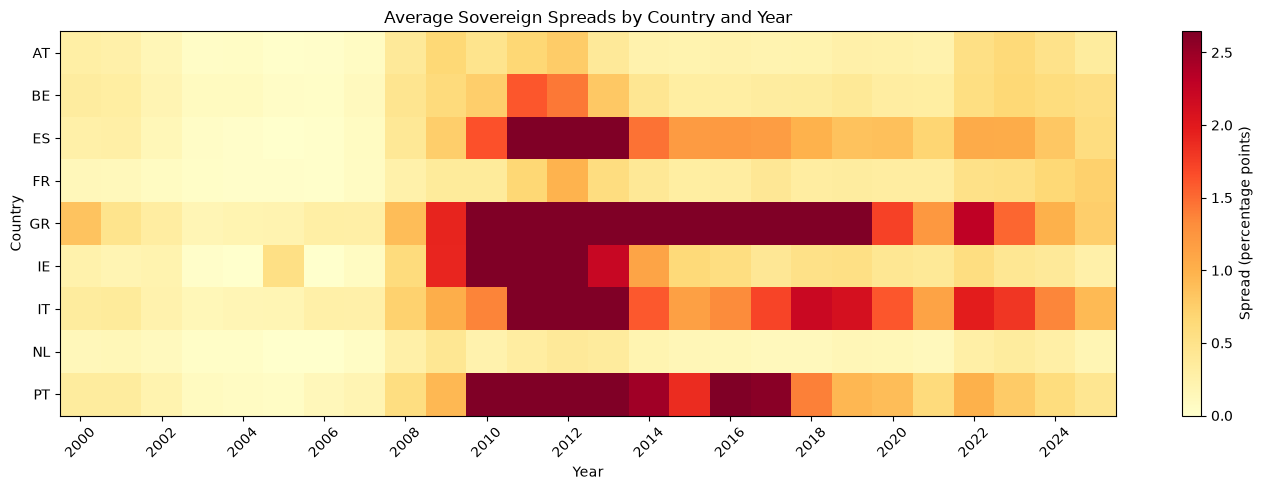

In [32]:

import matplotlib.pyplot as plt
import numpy as np

# Calculate annual average spreads by country
spread_yearly = (
    df_spread
    .assign(Year=df_spread["Date"].dt.year)
    .groupby(["Country", "Year"])["10Y_Spread"]
    .mean()
    .unstack("Year")
)

# Create heatmap
fig, ax = plt.subplots(figsize=(14, 5))

# Cap the colour scale at the 90th percentile
# so extreme observations do not obscure other patterns
colour_limit = np.nanpercentile(spread_yearly.values, 90)

im = ax.imshow(
    spread_yearly,
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=colour_limit
)

# Axis labels
ax.set_yticks(range(len(spread_yearly.index)))
ax.set_yticklabels(spread_yearly.index)

ax.set_xticks(range(0, len(spread_yearly.columns), 2))
ax.set_xticklabels(spread_yearly.columns[::2], rotation=45)

ax.set_title("Average Sovereign Spreads by Country and Year")
ax.set_xlabel("Year")
ax.set_ylabel("Country")

fig.colorbar(im, ax=ax, label="Spread (percentage points)")

plt.tight_layout()
plt.show()


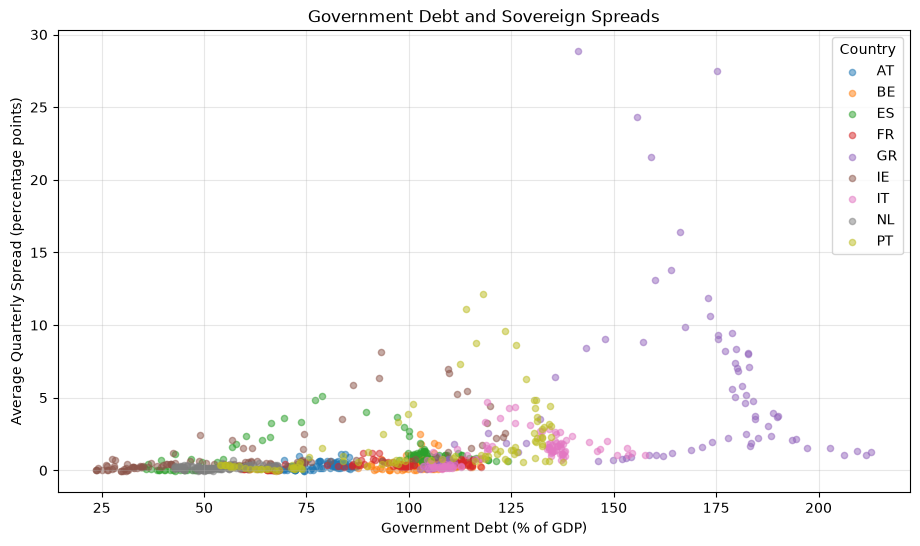

In [33]:

# Calculate quarterly average spreads
# This avoids plotting the same quarterly debt value
# three times for each month's spread.

quarterly_analysis = (
    df_spread
    .groupby(["Country", "Quarter"])
    .agg(
        Debt_GDP=("Debt_GDP", "first"),
        Avg_Spread=("10Y_Spread", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(11, 6))

# Plot each country separately
for country in quarterly_analysis["Country"].unique():

    data = quarterly_analysis[
        quarterly_analysis["Country"] == country
    ]

    plt.scatter(
        data["Debt_GDP"],
        data["Avg_Spread"],
        label=country,
        alpha=0.5,
        s=20
    )

plt.title("Government Debt and Sovereign Spreads")
plt.xlabel("Government Debt (% of GDP)")
plt.ylabel("Average Quarterly Spread (percentage points)")
plt.legend(title="Country")
plt.grid(True, alpha=0.3)

plt.show()


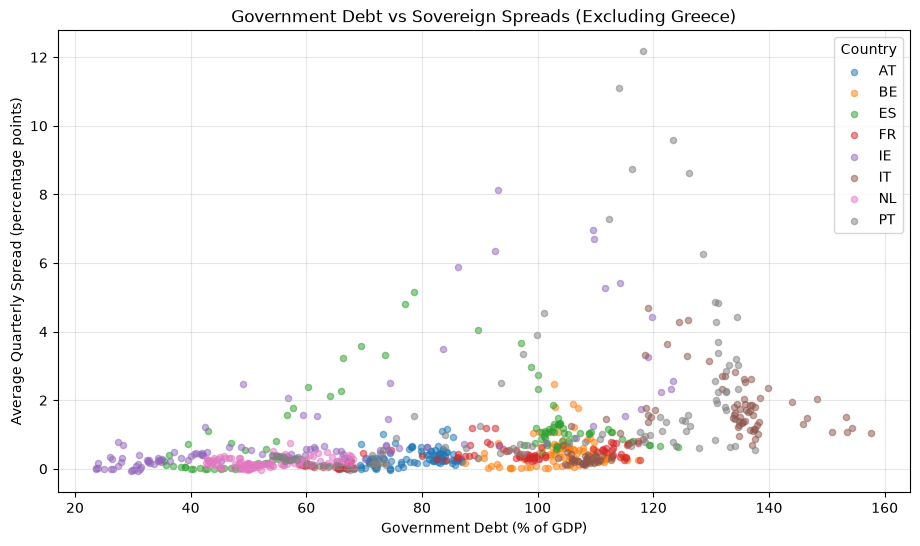

In [34]:

# Exclude Greece from the quarterly dataset
quarterly_no_greece = quarterly_analysis[
    quarterly_analysis["Country"] != "GR"
]

plt.figure(figsize=(11, 6))

# Plot each remaining country
for country in quarterly_no_greece["Country"].unique():

    data = quarterly_no_greece[
        quarterly_no_greece["Country"] == country
    ]

    plt.scatter(
        data["Debt_GDP"],
        data["Avg_Spread"],
        label=country,
        alpha=0.5,
        s=20
    )

plt.title("Government Debt vs Sovereign Spreads (Excluding Greece)")
plt.xlabel("Government Debt (% of GDP)")
plt.ylabel("Average Quarterly Spread (percentage points)")
plt.legend(title="Country")
plt.grid(True, alpha=0.3)

plt.show()


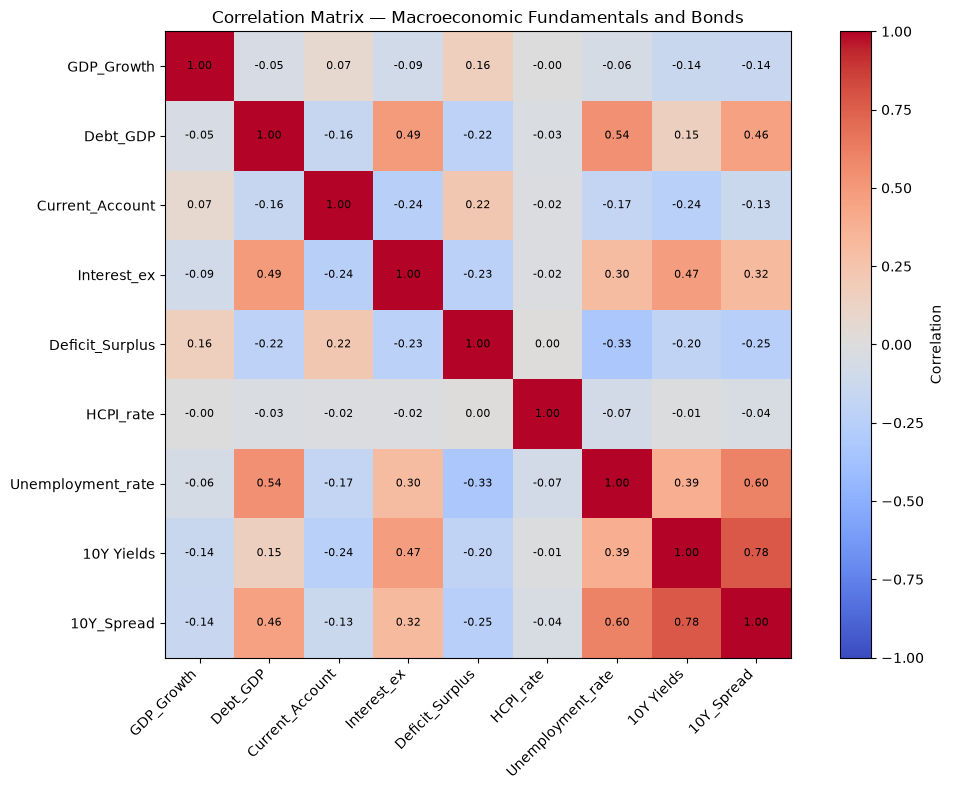

In [35]:

import matplotlib.pyplot as plt
import numpy as np

# Select explanatory and dependent variables
variables = [
    "GDP_Growth",
    "Debt_GDP",
    "Current_Account",
    "Interest_ex",
    "Deficit_Surplus",
    "HCPI_rate",
    "Unemployment_rate",
    "10Y Yields",
    "10Y_Spread"
]

# Exclude Germany to avoid mechanically zero spreads
corr = df_spread[variables].corr()

# Create correlation heatmap
fig, ax = plt.subplots(figsize=(11, 8))

im = ax.imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(variables)))
ax.set_yticks(range(len(variables)))

ax.set_xticklabels(variables, rotation=45, ha="right")
ax.set_yticklabels(variables)

# Display correlation coefficients
for i in range(len(variables)):
    for j in range(len(variables)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation Matrix — Macroeconomic Fundamentals and Bonds")

plt.tight_layout()
plt.show()


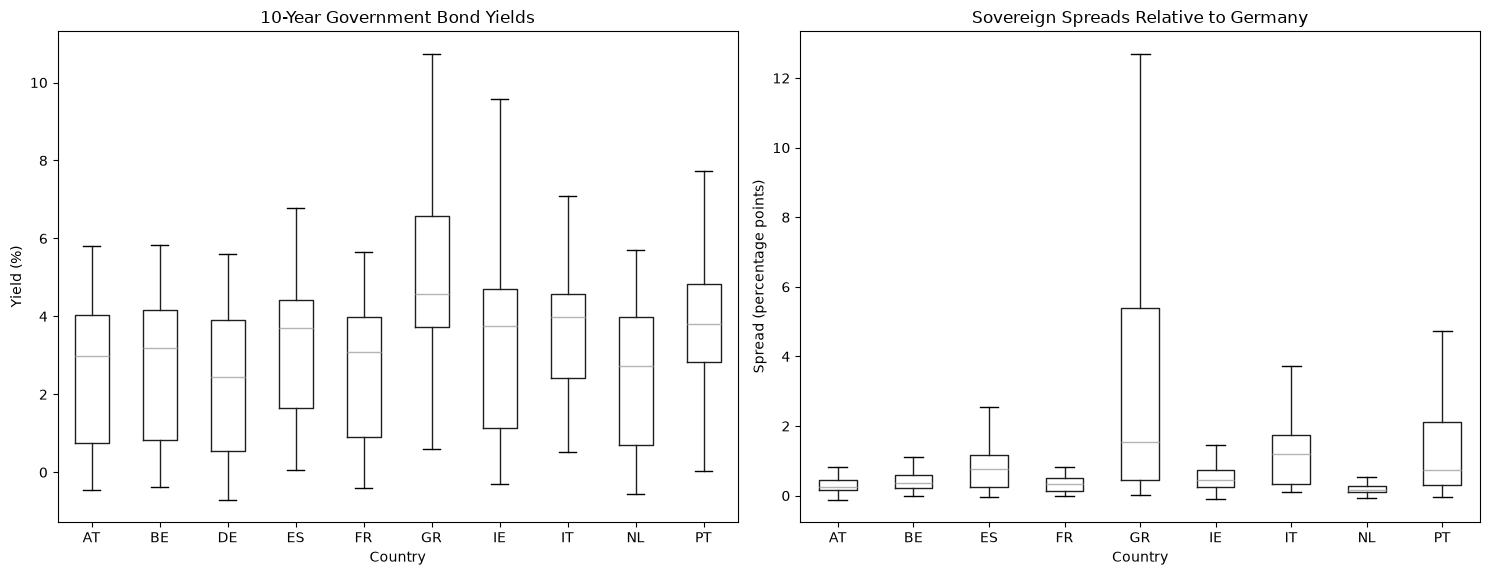

In [36]:

# Create two boxplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Government bond yields
df.boxplot(
    column="10Y Yields",
    by="Country",
    ax=axes[0],
    showfliers=False,
    grid=False
)

axes[0].set_title("10-Year Government Bond Yields")
axes[0].set_xlabel("Country")
axes[0].set_ylabel("Yield (%)")

# Sovereign spreads excluding Germany
df_spread.boxplot(
    column="10Y_Spread",
    by="Country",
    ax=axes[1],
    showfliers=False,
    grid=False
)

axes[1].set_title("Sovereign Spreads Relative to Germany")
axes[1].set_xlabel("Country")
axes[1].set_ylabel("Spread (percentage points)")

plt.suptitle("")
plt.tight_layout()
plt.show()


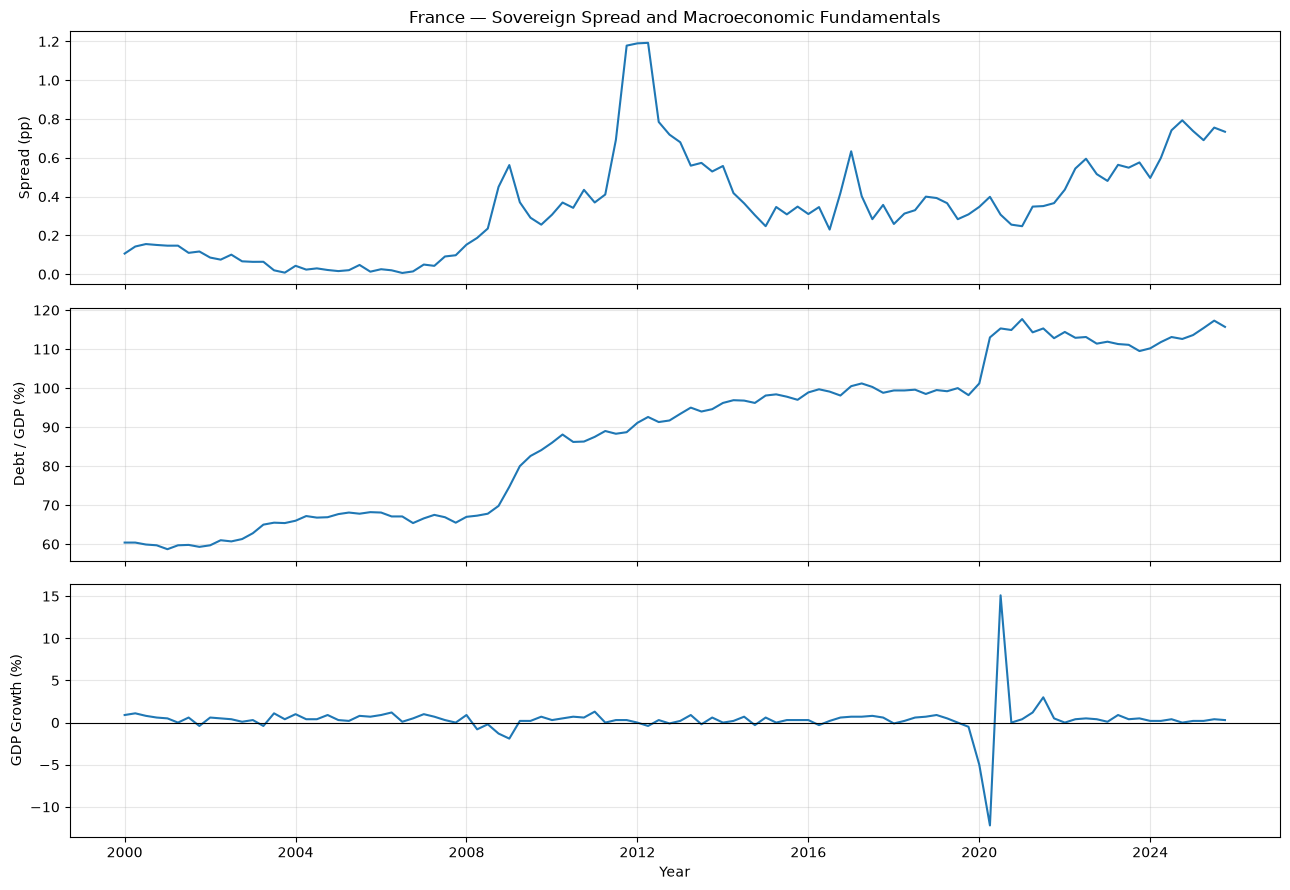

In [37]:

# Select France
france = df[df["Country"] == "FR"].copy()

# Create a quarterly date identifier
france["Q_Date"] = france["Date"].dt.to_period("Q")

# Aggregate data by quarter
france_quarterly = france.groupby("Q_Date").agg(
    Spread=("10Y_Spread", "mean"),
    Debt=("Debt_GDP", "first"),
    GDP_Growth=("GDP_Growth", "first")
)

# Convert quarterly index to dates
france_quarterly.index = france_quarterly.index.to_timestamp()

# Create three aligned graphs
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

axes[0].plot(
    france_quarterly.index,
    france_quarterly["Spread"]
)
axes[0].set_ylabel("Spread (pp)")
axes[0].set_title("France — Sovereign Spread and Macroeconomic Fundamentals")

axes[1].plot(
    france_quarterly.index,
    france_quarterly["Debt"]
)
axes[1].set_ylabel("Debt / GDP (%)")

axes[2].plot(
    france_quarterly.index,
    france_quarterly["GDP_Growth"]
)
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_ylabel("GDP Growth (%)")
axes[2].set_xlabel("Year")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
